# Gaussian process classification on XOR

A stationary RBF kernel and a squared DotProduct kernel fit the same 200 XOR points from seed zero. The probability contours show how each kernel models the two crossing decision boundaries.

The [scikit-learn gallery source](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/gaussian_process/plot_gpc_xor.py)
is by the scikit-learn developers and licensed under BSD-3-Clause. See
[Gaussian process license notices](../../LICENSES/gaussian-process-NOTICES).

Python supplies the shared inputs, executes the pinned scikit-learn reference, compares results and draws both sets of plots. Moxie fits and predicts in native Mojo.

In [1]:
import runpy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpc_xor")

reference = runpy.run_path(str(ROOT / "tests/gaussian_process/classification/parity.py"))
Classifier, kernels = reference["pinned_classifier"]()

## Fit the pinned scikit-learn model

In [2]:
rng = np.random.RandomState(0)
X = rng.randn(200, 2)
y = np.logical_xor(X[:, 0] > 0, X[:, 1] > 0).astype(np.int64)
axis = np.linspace(-3, 3, 50)
xx, yy = np.meshgrid(axis, axis)
titles = ("RBF", "Squared DotProduct")
configured_kernels = (1.0 * kernels.RBF(1.15), 1.0 * kernels.DotProduct(sigma_0=1.0)**2)
fit_options = {"warm_start": True}

query = np.column_stack((xx.ravel(), yy.ravel()))
nb.share(X=X, y=y, query=query)
expected = []
for kernel in configured_kernels:
    model = Classifier(kernel=kernel, **fit_options).fit(X, y)
    expected.append(dict(
        classes=model.classes_,
        predictions=model.predict(query),
        probabilities=model.predict_proba(query),
        theta=model.kernel_.theta,
        lml=model.log_marginal_likelihood(model.kernel_.theta),
        score=model.score(X, y),
    ))

/home/strgenix/postdoc/projects/mojods/porting-sklearn/scikit-learn/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


## Fit the native Mojo model

Labels are Int64 arrays. Fitted kernel metadata is available through `kernel_()`.

In [3]:
%%mojo classification
from moxie.gaussian_process import GaussianProcessClassifier
from moxie.gaussian_process.kernels import DotProduct, Kernel, RBF
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var query = load("query")
    var configured_kernels: List[Kernel] = [1.0 * RBF(1.15), 1.0 * (DotProduct() ** 2.0)]
    for i in range(len(configured_kernels)):
        var suffix = String(i)
        var model = GaussianProcessClassifier(configured_kernels[i], warm_start=True)
        _ = model.fit(X, y)
        var theta = model.kernel_().theta()
        save("classes_" + suffix, model.classes_())
        save("predictions_" + suffix, model.predict(query))
        save("probabilities_" + suffix, model.predict_proba(query))
        save("theta_" + suffix, theta)
        save_floats("lml_" + suffix, [model.log_marginal_likelihood(theta^).value])
        save_floats("score_" + suffix, [model.score(X, y)])

## Compare fitted results

The checks cover the full query grid and require exact agreement for sorted classes, predictions and training accuracy.

The squared DotProduct fit reaches the upper bound on its constant multiplier and emits a convergence warning.

In [4]:
native = nb.results["classification"]
actual = []
exact = {"classes", "predictions", "score"}
for i, (title, reference_result) in enumerate(zip(titles, expected, strict=True)):
    result = {key: native[f"{key}_{i}"] for key in reference_result}
    for key in ("lml", "score"):
        result[key] = result[key].item()
    actual.append(result)
    for key, expected_value in reference_result.items():
        assert np.asarray(result[key]).dtype == np.asarray(expected_value).dtype, (title, key)
        nb.compare(
            f"{title} · {key}", expected_value, result[key], exact=key in exact,
            rtol=1e-6, atol=1e-7,
            reason="" if key in exact else
            "Allows for differences in Float64 reduction order and optimizer stopping points.",
        )

nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
RBF · classes,PASS,"(2,)","(2,)",,,exact,0 mismatches,
RBF · predictions,PASS,"(2500,)","(2500,)",,,exact,0 mismatches,
RBF · probabilities,PASS,"(2500, 2)","(2500, 2)",1.12e-07,4.24e-07,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
RBF · theta,PASS,"(2,)","(2,)",1.68e-09,3.81e-09,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
RBF · lml,PASS,(),(),7.39e-09,3.05e-10,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
RBF · score,PASS,(),(),,,exact,0 mismatches,
Squared DotProduct · classes,PASS,"(2,)","(2,)",,,exact,0 mismatches,
Squared DotProduct · predictions,PASS,"(2500,)","(2500,)",,,exact,0 mismatches,
Squared DotProduct · probabilities,PASS,"(2500, 2)","(2500, 2)",4.6e-11,4.54e-10,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.
Squared DotProduct · theta,PASS,"(2,)","(2,)",9.36e-13,2.05e-13,"rtol=1e-06, atol=1e-07",,Allows for differences in Float64 reduction order and optimizer stopping points.


## Probability surfaces

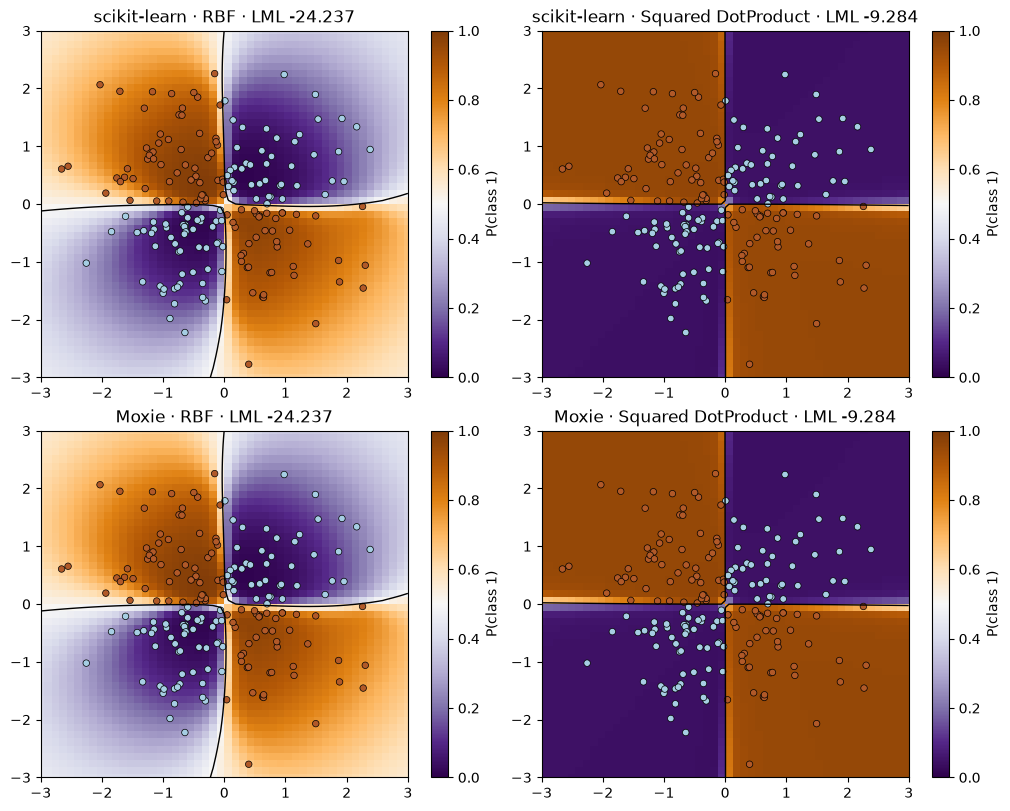

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for row, (backend, results) in enumerate((("scikit-learn", expected), ("Moxie", actual))):
    for col, (title, result) in enumerate(zip(titles, results, strict=True)):
        ax = axes[row, col]
        probabilities = result["probabilities"]
        positive = probabilities[:, 1].reshape(xx.shape)
        image = ax.pcolormesh(xx, yy, positive, cmap="PuOr_r", vmin=0, vmax=1, shading="auto")
        ax.contour(xx, yy, positive, levels=[0.5], colors="black", linewidths=1)
        ax.scatter(*X.T, c=y, cmap="Paired", edgecolors="black", linewidths=0.5, s=22)
        fig.colorbar(image, ax=ax, label="P(class 1)")
        ax.set_title(f"{backend} · {title} · LML {result['lml']:.3f}")
        ax.set(xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()))
plt.show()